# EDA

Мои инструменты: фьючерсы на нефть, газ и нефтепродукты (CL, NG, BZ, RB, HO)
и 30 акций из трёх секторов. Время везде нью-йоркское.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display
import pandas_market_calendars as mcal
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf

ROOT = Path.cwd().parents[1]
FUTURES_DIR = ROOT / "data/processed/futures_continuous"
STOCKS_DIR = ROOT / "data/processed/stocks"

config = yaml.safe_load(open(ROOT / "config/instruments.yaml"))
my_groups = config["team"]["iura"]

futures = {}
for group in my_groups["futures"]:
    for item in config["futures"][group]:
        futures[item["ticker"]] = group

stocks = {}
for group in my_groups["stocks"]:
    for item in config["stocks"][group]:
        stocks[item["ticker"]] = group

print("Фьючерсы:", list(futures))
for group in my_groups["stocks"]:
    print(group, [t for t, g in stocks.items() if g == group])

Фьючерсы: ['CL', 'NG', 'BZ', 'RB', 'HO']
consumer_discretionary ['AMZN', 'TSLA', 'HD', 'MCD', 'TJX', 'SBUX', 'LOW', 'BKNG', 'MAR', 'HLT']
consumer_staples ['WMT', 'COST', 'PG', 'KO', 'PM', 'PEP', 'MO', 'MDLZ', 'CL', 'TGT']
industrials ['GE', 'CAT', 'RTX', 'UNP', 'DE', 'ETN', 'BA', 'UBER', 'LMT', 'PH']


## 1. Данные и их качество

In [2]:
def load_futures(ticker, timeframe="15min"):
    df = pd.read_parquet(FUTURES_DIR / f"{ticker}_{timeframe}.parquet")
    df["time"] = df["time"].dt.tz_convert("America/New_York")
    df["ticker"] = ticker
    return df


def load_stock(ticker, timeframe="15min"):
    columns = ["time", "adj_open", "adj_high", "adj_low", "adj_close",
               "split_adj_volume", "trades", "in_session"]
    df = pd.read_parquet(STOCKS_DIR / f"{ticker}_{timeframe}.parquet", columns=columns)
    df = df.rename(columns={"adj_open": "open", "adj_high": "high", "adj_low": "low",
                            "adj_close": "close", "split_adj_volume": "volume"})
    df["time"] = df["time"].dt.tz_convert("America/New_York")
    df["ticker"] = ticker
    return df


fut = pd.concat([load_futures(t) for t in futures], ignore_index=True)
stk = pd.concat([load_stock(t) for t in stocks], ignore_index=True)
print("Фьючерсы:", len(fut), "строк, столбцы:", list(fut.columns))
print("Акции:", len(stk), "строк, столбцы:", list(stk.columns))

# у NG 20.02.2025 один бар задвоился, оставляем тот, где основной объём
fut = fut.drop_duplicates(["ticker", "time"], keep="last")

Фьючерсы: 568900 строк, столбцы: ['time', 'session_end_date', 'contract', 'open', 'high', 'low', 'close', 'volume', 'transactions', 'factor', 'ticker']
Акции: 1464268 строк, столбцы: ['time', 'open', 'high', 'low', 'close', 'volume', 'trades', 'in_session', 'ticker']


In [3]:
def passport(df):
    rows = []
    for ticker, g in df.groupby("ticker"):
        bad_ohlc = ((g["high"] < g[["open", "close"]].max(axis=1))
                    | (g["low"] > g[["open", "close"]].min(axis=1))
                    | (g["low"] <= 0))
        rows.append({
            "ticker": ticker,
            "начало": g["time"].min().date(),
            "конец": g["time"].max().date(),
            "баров": len(g),
            "NaN": g.isna().sum().sum(),
            "дубли": g["time"].duplicated().sum(),
            "плохие OHLC": bad_ohlc.sum(),
            "нулевой объём": (g["volume"] == 0).sum(),
        })
    return pd.DataFrame(rows).set_index("ticker")


display(passport(fut))

stk_passport = passport(stk)
stk_passport["сектор"] = stk_passport.index.map(stocks)
stk_passport.groupby("сектор").agg(
    тикеров=("баров", "size"), баров_мин=("баров", "min"), баров_макс=("баров", "max"),
    NaN=("NaN", "sum"), дубли=("дубли", "sum"),
    плохие_OHLC=("плохие OHLC", "sum"), нулевой_объём=("нулевой объём", "sum"))

,начало,конец,баров,NaN,дубли,плохие OHLC,нулевой объём
ticker,,,,,,,
BZ,2021-11-14,2026-09-30,111816,0,0,0,0
CL,2021-11-14,2026-09-30,115259,0,0,0,0
HO,2021-11-14,2026-09-30,113561,0,0,0,0
NG,2021-11-14,2026-09-30,115289,0,0,0,0
RB,2021-11-14,2026-09-30,112974,0,0,0,0


,тикеров,баров_мин,баров_макс,NaN,дубли,плохие_OHLC,нулевой_объём
сектор,,,,,,,
consumer_discretionary,10,35739,77961,0,0,0,0
consumer_staples,10,38661,62382,0,0,0,0
industrials,10,34243,70135,0,0,0,0


In [4]:
timeframes = [
    ("фьючерсы", FUTURES_DIR, futures, ["15min", "1hour", "4hour"]),
    ("акции", STOCKS_DIR, stocks, ["5min", "15min", "1hour", "4hour", "1day"]),
]

rows = []
for market, folder, tickers, tf_list in timeframes:
    for tf in tf_list:
        for ticker in tickers:
            time = pd.read_parquet(folder / f"{ticker}_{tf}.parquet", columns=["time"])["time"]
            rows.append({"рынок": market, "таймфрейм": tf,
                         "строк": len(time), "дубли времени": time.duplicated().sum()})

pd.DataFrame(rows).groupby(["рынок", "таймфрейм"], sort=False).sum()

строк  дубли времени
рынок    таймфрейм                        
фьючерсы 15min       568900              1
         1hour       144107              1
         4hour        43828           4823
акции    5min       3810599              0
         15min      1464268              0
         1hour       445350              0
         4hour       134587              0
         1day         36690              0

У фьючерсов нет 5-минутных и дневных баров. В 4-часовых много дублей: бар на границе сессии
разрезан на два (как у NG выше), поэтому их не берём. Дальше работаю с 15-минутными,
а часы и дни собираю из них сам.

Как считаю пропуски: беру расписание биржи из pandas_market_calendars (NYSE для акций,
CME Globex Energy для фьючерсов) и смотрю, каких 15-минутных баров не хватает.
Праздники и короткие дни там в основном учтены, где календарь ошибается — ниже.

,пропущено,% пропусков,лишние
ticker,,,
BZ,3585,3.11,30
CL,144,0.12,32
HO,1842,1.60,32
NG,114,0.10,32
RB,2429,2.11,32


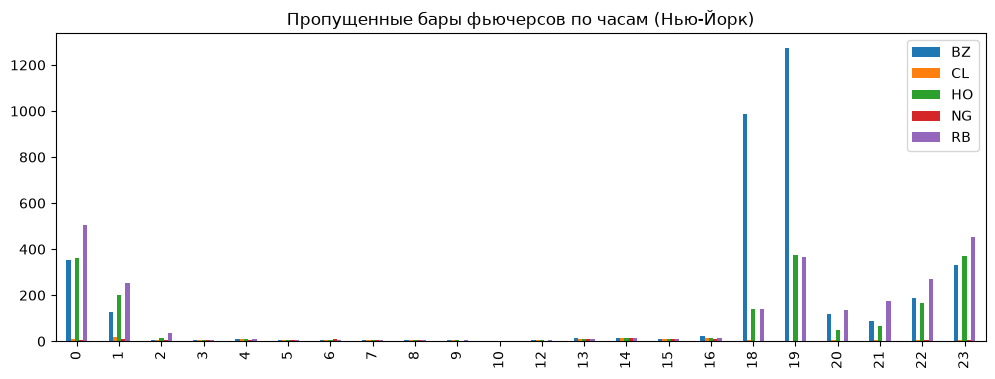

пропусков с 18:00 до 3:00: 94%
CL, дни с дневными пропусками: {'2025-11-28': 22, '2025-12-24': 13, '2024-12-24': 13, '2025-07-04': 6}


2022-09-05    6
2023-09-04    6
2024-09-02    6
2024-11-29    4
2025-09-01    6
2025-11-28    4
Name: count, dtype: int64

In [5]:
def expected_times(calendar, start="2021-11-15", end="2026-09-30"):
    schedule = mcal.get_calendar(calendar).schedule(start, end, tz="America/New_York")
    parts = [pd.date_range(o, c, freq="15min", inclusive="left")
             for o, c in zip(schedule["market_open"], schedule["market_close"])]
    return parts[0].append(parts[1:])  # склеиваем все дни в один список


def missing_bars(df, expected):
    rows, missing_times = [], {}
    for ticker, g in df.groupby("ticker"):
        actual = pd.DatetimeIndex(g["time"])
        missing = expected.difference(actual)
        missing_times[ticker] = missing
        rows.append({"ticker": ticker, "пропущено": len(missing),
                     "% пропусков": round(100 * len(missing) / len(expected), 2),
                     "лишние": len(actual.difference(expected))})
    return pd.DataFrame(rows).set_index("ticker"), missing_times


fut_expected = expected_times("CMEGlobex_Energy")
fut_missing, fut_missing_times = missing_bars(fut, fut_expected)
display(fut_missing)

hours = pd.DataFrame({t: pd.Series(m.hour).value_counts() for t, m in fut_missing_times.items()})
hours.fillna(0).sort_index().plot.bar(figsize=(12, 4), title="Пропущенные бары фьючерсов по часам (Нью-Йорк)")
plt.show()

night = sum(((m.hour >= 18) | (m.hour < 3)).sum() for m in fut_missing_times.values())
total = sum(len(m) for m in fut_missing_times.values())
print(f"пропусков с 18:00 до 3:00: {night / total:.0%}")

cl_missing = fut_missing_times["CL"]
cl_day = cl_missing[(cl_missing.hour >= 3) & (cl_missing.hour < 18)]
print("CL, дни с дневными пропусками:", pd.Series(cl_day.strftime("%Y-%m-%d")).value_counts().head(4).to_dict())

cl_extra = pd.DatetimeIndex(fut.loc[fut["ticker"] == "CL", "time"]).difference(fut_expected)
pd.Series(cl_extra.date).value_counts().sort_index()

Почти все пропуски у фьючерсов (94%) вечером и ночью, с 18:00 до 3:00, когда торгов мало:
просто 15 минут без сделок. Больше всего у BZ, около 3%. Дневных пропусков мало, у CL в основном это 24 декабря
и 4 июля, когда биржа закрывается раньше, а календарь этого не знает, и 28.11.2025 — сбой на CME
(отказало охлаждение в дата-центре, торги стояли больше 10 часов).

Лишние бары — это День труда и пятница после Дня благодарения. Календарь думает,
что биржа в эти дни закрылась раньше, а торги шли. У остальных фьючерсов так же.

,пропущено,% пропусков,лишние
ticker,,,
BKNG,364,1.15,0
MO,1,0.00,0
PH,2,0.01,0
UBER,2,0.01,0


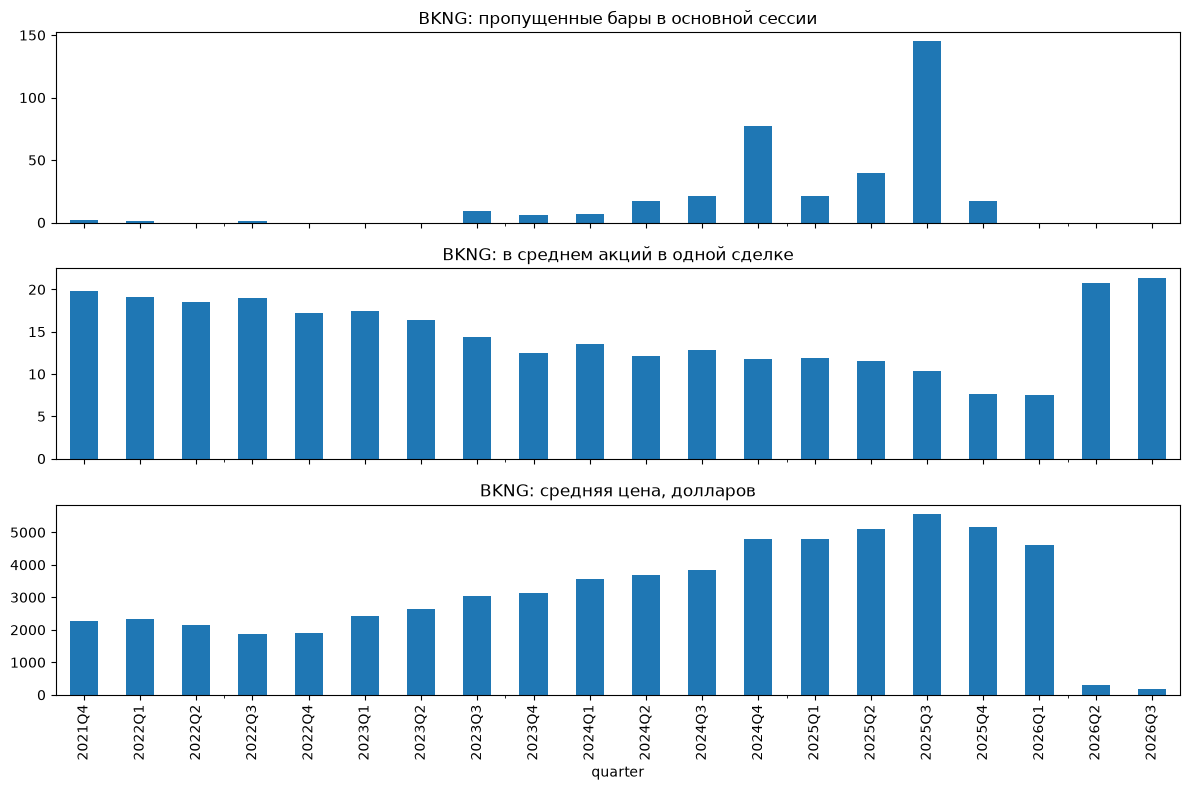

In [6]:
stk_missing, stk_missing_times = missing_bars(stk[stk["in_session"]], expected_times("NYSE"))
display(stk_missing[stk_missing["пропущено"] > 0])

bkng = pd.read_parquet(STOCKS_DIR / "BKNG_15min.parquet",
                       columns=["time", "close", "volume", "trades", "in_session"])
bkng = bkng[bkng["in_session"]]
bkng["quarter"] = bkng["time"].dt.tz_convert("America/New_York").dt.tz_localize(None).dt.to_period("Q")

by_quarter = bkng.groupby("quarter")
bkng_q = pd.DataFrame({
    "средняя цена": by_quarter["close"].mean().round(),
    "акций в сделке": (by_quarter["volume"].sum() / by_quarter["trades"].sum()).round(1),
})

missing_quarter = stk_missing_times["BKNG"].tz_localize(None).to_period("Q")
bkng_q["пропущено баров"] = pd.Series(missing_quarter).value_counts()
bkng_q = bkng_q.fillna(0)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
bkng_q["пропущено баров"].plot.bar(ax=axes[0], title="BKNG: пропущенные бары в основной сессии")
bkng_q["акций в сделке"].plot.bar(ax=axes[1], title="BKNG: в среднем акций в одной сделке")
bkng_q["средняя цена"].plot.bar(ax=axes[2], title="BKNG: средняя цена, долларов")
plt.tight_layout()
plt.show()

У акций в основной сессии пропусков почти нет, кроме BKNG.

Бар появляется, только если была сделка от 100 акций (полный лот). BKNG стоила 4–6 тыс. долларов,
и в сделке в среднем было около 10 акций, поэтому в спокойные 15 минут таких сделок могло
вообще не быть. С 3 ноября 2025 для акций ценой от 1000 до 10 000 долларов полный лот стал 10 акций
(правило SEC), и пропуски пропали.

## 2. Доходности

Доходность считаю как логарифм отношения цен закрытия, в процентах. У акций беру только
основную сессию. Первый бар сессии считается от закрытия прошлой, в нём скачок через ночь
или выходные, поэтому смотрю его отдельно.

In [7]:
stk_main = stk[stk["in_session"]].copy()
stk_main["session_end_date"] = stk_main["time"].dt.date.astype(str)
stk_main["sector"] = stk_main["ticker"].map(stocks)


def add_returns(df):
    df = df.sort_values(["ticker", "time"]).copy()
    df["ret"] = np.log(df["close"] / df.groupby("ticker")["close"].shift()) * 100
    df["first_bar"] = df["session_end_date"] != df.groupby("ticker")["session_end_date"].shift()
    return df


fut = add_returns(fut)
stk_main = add_returns(stk_main)

for market, df in [("фьючерсы", fut), ("акции", stk_main)]:
    kurt_all = df.groupby("ticker")["ret"].apply(pd.Series.kurt).median()
    kurt_in = df[~df["first_bar"]].groupby("ticker")["ret"].apply(pd.Series.kurt).median()
    print(f"{market}: эксцесс со скачками через ночь {kurt_all:.0f}, без них {kurt_in:.0f}")

фьючерсы: эксцесс со скачками через ночь 119, без них 53
акции: эксцесс со скачками через ночь 66, без них 10


In [8]:
def ret_stats(df):
    g = df.groupby("ticker")["ret"]
    return pd.DataFrame({"среднее": g.mean(), "std": g.std(), "мин": g.min(), "макс": g.max(),
                         "асимметрия": g.skew(), "эксцесс": g.apply(pd.Series.kurt)}).round(3)


fut_in = fut[~fut["first_bar"]]
stk_in = stk_main[~stk_main["first_bar"]]
display(ret_stats(fut_in))

stk_stats = ret_stats(stk_in)
stk_stats.groupby(stk_stats.index.map(stocks)).median().rename_axis("сектор")

,среднее,std,мин,макс,асимметрия,эксцесс
ticker,,,,,,
BZ,0.000,0.260,-11.051,4.939,-1.485,58.114
CL,-0.000,0.271,-11.000,5.261,-1.399,53.281
HO,0.001,0.276,-12.258,4.440,-1.397,58.489
NG,-0.002,0.400,-7.665,6.546,-0.158,12.455
RB,0.000,0.240,-9.272,4.520,-0.891,33.798


,среднее,std,мин,макс,асимметрия,эксцесс
сектор,,,,,,
consumer_discretionary,-0.0000,0.2550,-2.8800,4.9050,0.2225,10.597
consumer_staples,0.0005,0.1930,-1.9275,2.5155,-0.0935,6.133
industrials,0.0000,0.2795,-3.9975,5.2420,0.1550,12.942


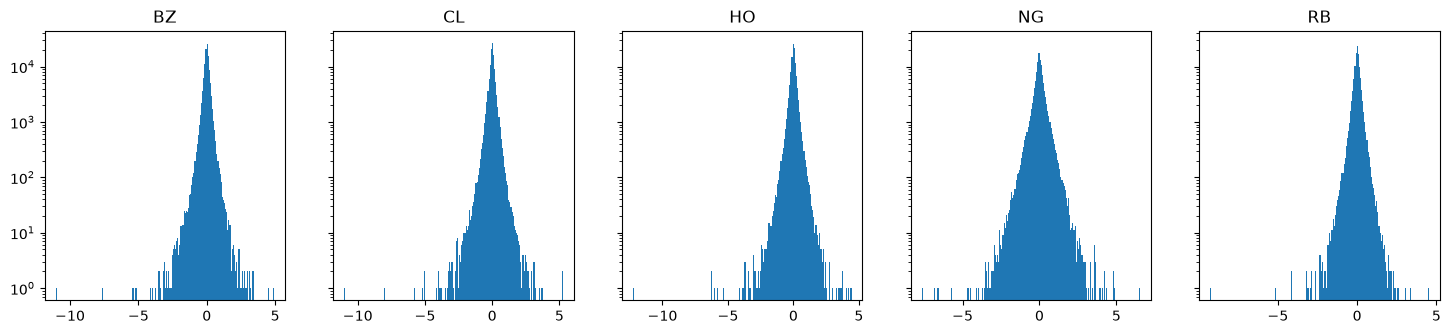

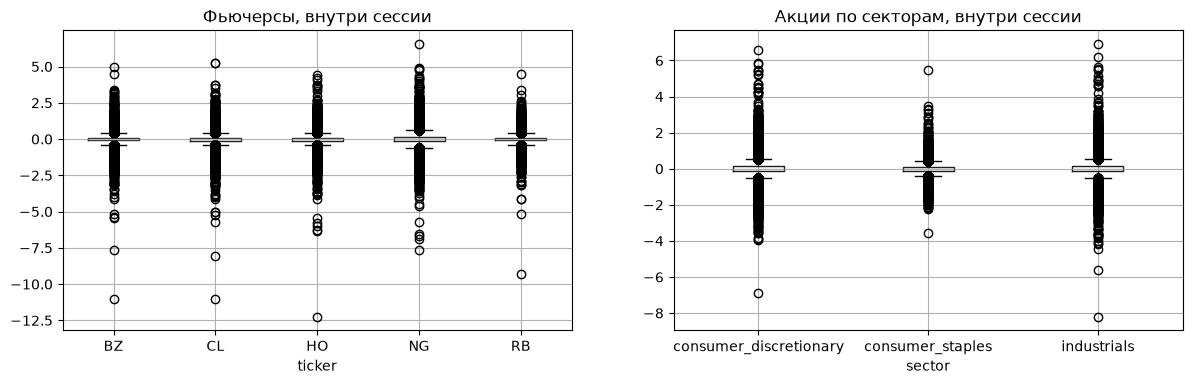

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5), sharey=True)
for ax, (ticker, g) in zip(axes, fut_in.groupby("ticker")):
    ax.hist(g["ret"].dropna(), bins=200, log=True)
    ax.set_title(ticker)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fut_in.boxplot(column="ret", by="ticker", ax=axes[0])
stk_in.boxplot(column="ret", by="sector", ax=axes[1])
axes[0].set_title("Фьючерсы, внутри сессии")
axes[1].set_title("Акции по секторам, внутри сессии")
plt.suptitle("")
plt.show()

In [10]:
def horizon_returns(df, rule):
    if rule == "день":
        key = df["session_end_date"]
    else:
        key = df["time"].dt.tz_convert("UTC").dt.floor(rule)  # в UTC, иначе ошибка при переводе часов
    close = df.groupby(["ticker", key])["close"].last()
    return np.log(close / close.groupby(level="ticker").shift()) * 100


rows = []
for rule in ["15min", "1h", "4h", "день"]:
    for market, df in [("фьючерсы", fut), ("акции", stk_main)]:
        g = horizon_returns(df, rule).groupby(level="ticker")
        rows.append({"горизонт": rule, "рынок": market,
                     "std": g.std().median(), "эксцесс": g.apply(pd.Series.kurt).median()})
pd.DataFrame(rows).pivot(index="горизонт", columns="рынок").loc[["15min", "1h", "4h", "день"]].round(2)

std          эксцесс         
рынок    акции фьючерсы   акции фьючерсы
горизонт                                
15min     0.33     0.29   65.99   118.70
1h        0.63     0.57   20.36    31.54
4h        1.08     1.09    9.43    15.87
день      1.62     2.59    3.55     3.64

Внутри сессии средняя доходность почти ноль, больше всего скачет NG. Хвосты тяжёлые: эксцесс
у фьючерсов 12–58, у акций в среднем по секторам 6–13 (у нормального распределения 0). У нефти и нефтепродуктов
сильнее всего падения, до 9–12% за 15 минут.

Основная часть хвостов — скачки через ночь и выходные. Если их убрать, эксцесс у акций падает
с 66 до 10 (отчёты компаний выходят до открытия), у фьючерсов со 119 до 53.

Чем больше горизонт, тем меньше хвосты: на дневных доходностях эксцесс около 3,5.

## 3. Выбросы

Выброс ищу по modified z-score: насколько доходность дальше от медианы, если мерить в MAD
(медиана отклонений). Медиана и MAD почти не зависят от самих выбросов, в отличие от среднего и std.

In [11]:
def add_z(df):
    med = df.groupby("ticker")["ret"].transform("median")
    mad = (df["ret"] - med).abs().groupby(df["ticker"]).transform("median")
    df["z"] = 0.6745 * (df["ret"] - med) / mad  # modified z-score
    return df


fut = add_z(fut)
stk_main = add_z(stk_main)

rows = []
for market, df in [("фьючерсы", fut), ("акции", stk_main)]:
    q1 = df.groupby("ticker")["ret"].transform(lambda s: s.quantile(0.25))
    q3 = df.groupby("ticker")["ret"].transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    rows.append({"рынок": market,
                 "IQR 1.5, %": ((df["ret"] < q1 - 1.5 * iqr) | (df["ret"] > q3 + 1.5 * iqr)).mean() * 100,
                 "|z| > 3.5, %": (df["z"].abs() > 3.5).mean() * 100,
                 "|z| > 10, %": (df["z"].abs() > 10).mean() * 100})
pd.DataFrame(rows).set_index("рынок").round(2)

,"IQR 1.5, %","|z| > 3.5, %","|z| > 10, %"
рынок,,,
фьючерсы,8.84,4.99,0.23
акции,6.36,3.63,0.34


фьючерсы: выбросов 1322, из них первый бар сессии 20%, объём выше обычного 97%
акции: выбросов 3223, из них первый бар сессии 92%, объём выше обычного 94%


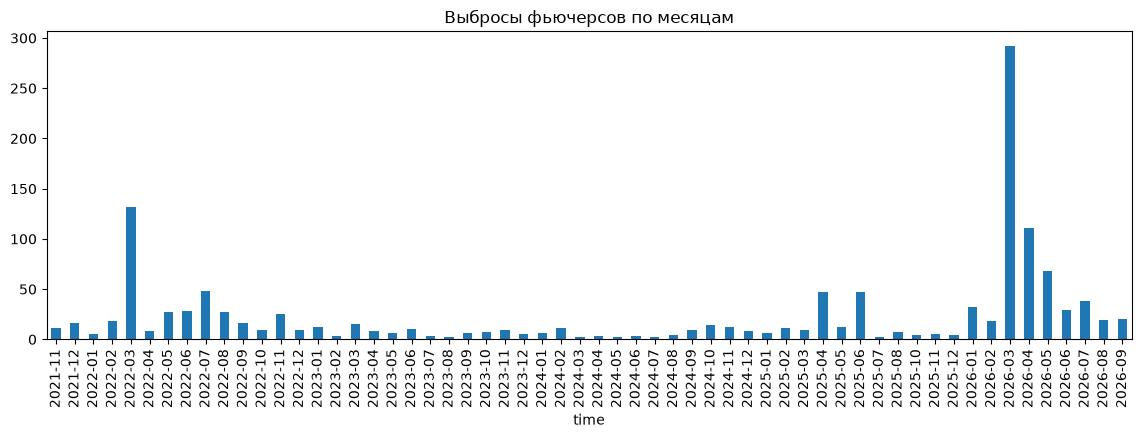

,time,ticker,ret,"изменение цены, %",first_bar,vol_ratio
943848,2022-05-18 09:30:00-04:00,TGT,-30.0,-25.9,True,38.8
968999,2024-11-20 09:30:00-05:00,TGT,-22.4,-20.1,True,39.9
318498,2024-08-13 09:30:00-04:00,SBUX,18.9,20.8,True,61.0
314700,2024-05-01 09:30:00-04:00,SBUX,-16.5,-15.2,True,19.1
959280,2023-11-15 09:30:00-05:00,TGT,15.6,16.9,True,24.4
122750,2024-10-24 09:30:00-04:00,TSLA,15.4,16.7,True,3.7
949023,2022-11-16 09:30:00-05:00,TGT,-15.0,-14.0,True,22.5
1331429,2022-11-01 09:30:00-04:00,UBER,15.0,16.1,True,8.0


In [12]:
for df in [fut, stk_main]:
    df["hm"] = df["time"].dt.strftime("%H:%M")
    df["vol_ratio"] = df["volume"] / df.groupby(["ticker", "hm"])["volume"].transform("median")

for market, df in [("фьючерсы", fut), ("акции", stk_main)]:
    out = df[df["z"].abs() > 10]
    print(f"{market}: выбросов {len(out)}, из них первый бар сессии {out['first_bar'].mean():.0%}, "
          f"объём выше обычного {(out['vol_ratio'] > 1).mean():.0%}")

out = fut[fut["z"].abs() > 10]
out.groupby(out["time"].dt.tz_localize(None).dt.to_period("M")).size().plot.bar(
    figsize=(14, 4), title="Выбросы фьючерсов по месяцам")
plt.show()

out = stk_main[stk_main["z"].abs() > 10].copy()
out["изменение цены, %"] = (np.exp(out["ret"] / 100) - 1) * 100
top = out.loc[out["ret"].abs().nlargest(8).index, ["time", "ticker", "ret", "изменение цены, %", "first_bar", "vol_ratio"]]
top.round(1)

При обычных порогах выбросов набирается 4–9% баров, а это просто обычные движения.
Поэтому беру порог побольше, |z| > 10.

Сильные выбросы — это настоящие движения, а не ошибки: почти у всех объём выше обычного для
этого времени. У акций 92% таких движений — первый бар дня: новость или отчёт компании вышли
до открытия (TGT −26% 18.05.2022 после отчёта, SBUX +21% 13.08.2024 после смены директора).
У фьючерсов выбросы собираются вокруг событий: март 2022 (конфликт на Украине), апрель 2025
(пошлины), июнь 2025 (конфликт Израиля и Ирана), март–апрель 2026 (Иран и Ормузский пролив).

Выбросы не удаляю.

## 4. Активность и волатильность по времени

Время нью-йоркское. Объём делю на средний бар своего тикера, чтобы тикеры с большими объёмами
не задавили остальные. День недели и месяц беру по торговой сессии.

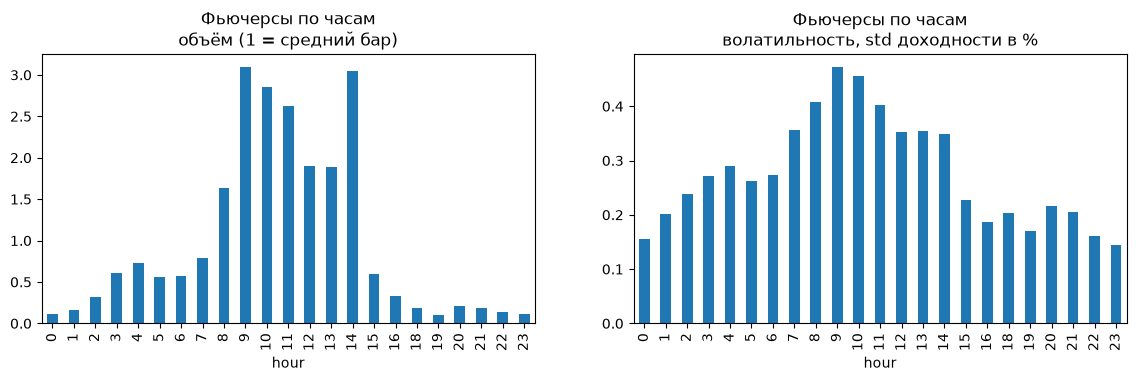

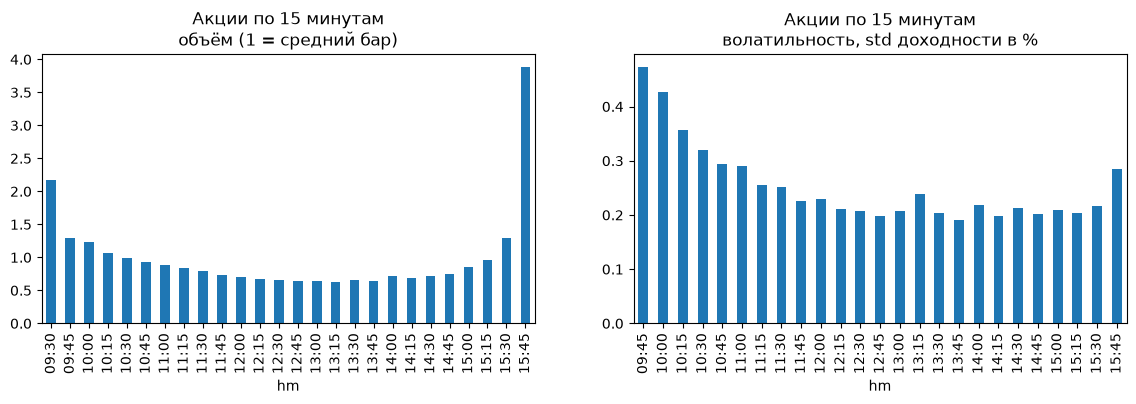

In [13]:
for df in [fut, stk_main]:
    df["rel_volume"] = df["volume"] / df.groupby("ticker")["volume"].transform("mean")
    df["hour"] = df["time"].dt.hour
    session = pd.to_datetime(df["session_end_date"])
    df["weekday"] = session.dt.dayofweek
    df["month"] = session.dt.month


def plot_profile(df, column, title):
    volume = df.groupby(column)["rel_volume"].mean()
    volatility = df[~df["first_bar"]].groupby(column)["ret"].std()
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
    volume.plot.bar(ax=axes[0], title=f"{title}\nобъём (1 = средний бар)")
    volatility.plot.bar(ax=axes[1], title=f"{title}\nволатильность, std доходности в %")
    plt.show()

plot_profile(fut, "hour", "Фьючерсы по часам")
plot_profile(stk_main, "hm", "Акции по 15 минутам")

Фьючерсы активнее всего в 9–11 и в 14 часов (в 14:30 на NYMEX считают расчётную цену дня),
ночью торгов почти нет. Волатильность тоже выше всего в 9–10. У акций буква U: много торгуют
на открытии и особенно в последние 15 минут перед закрытием, а волатильность выше всего
сразу после открытия и падает к обеду.

CL: std в 10:30 в день отчёта 0.53%, в другие дни 0.42%
NG: std в 10:30 в день отчёта 1.61%, в другие дни 0.57%


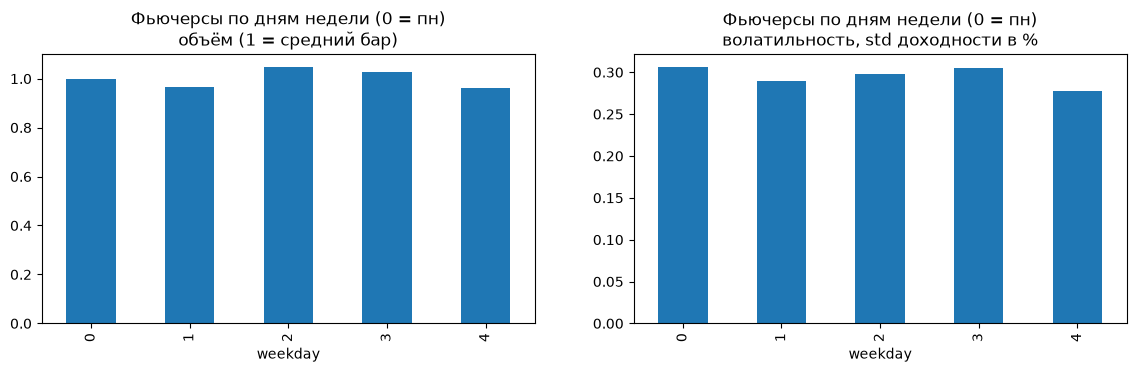

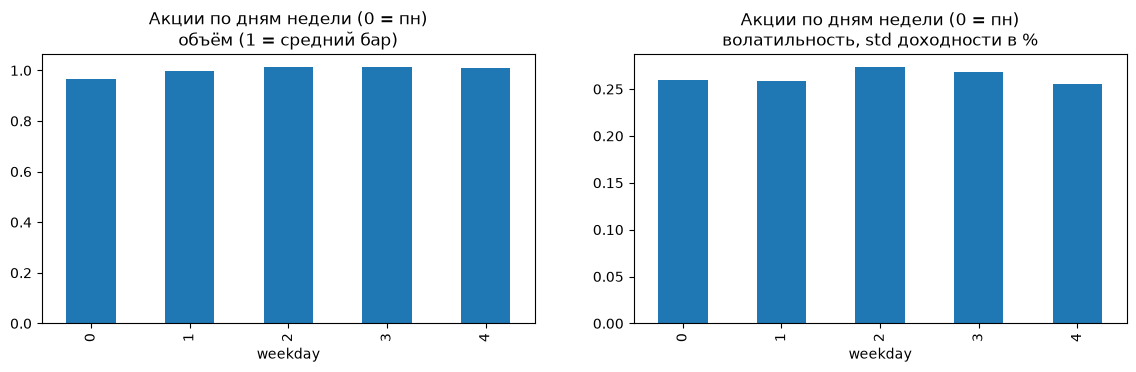

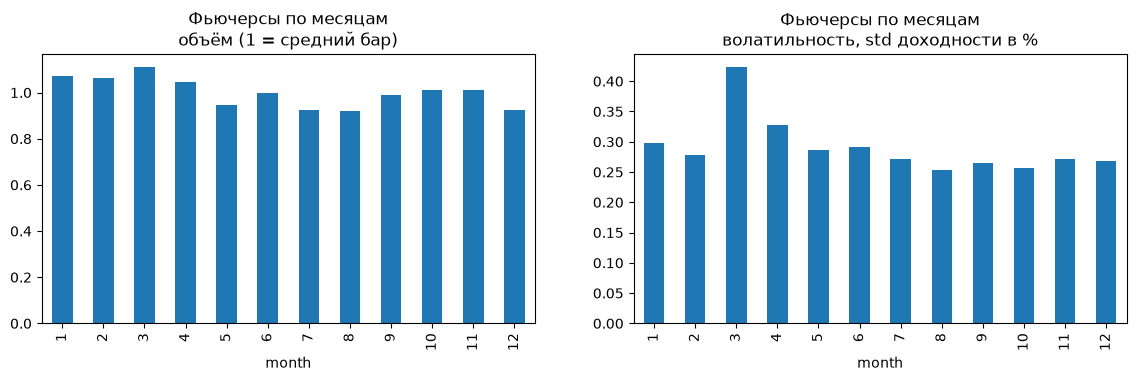

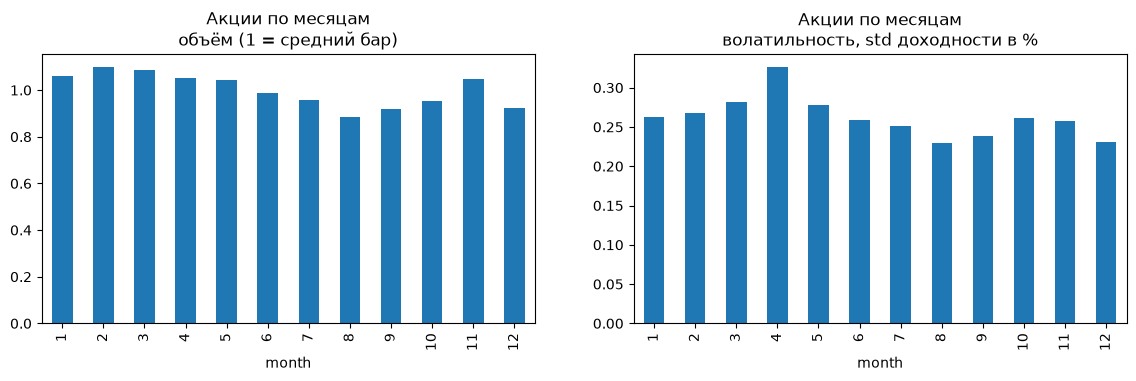

In [14]:
at_1030 = fut[~fut["first_bar"] & (fut["hm"] == "10:30")]
for ticker, day in [("CL", 2), ("NG", 3)]:
    b = at_1030[at_1030["ticker"] == ticker]
    print(f"{ticker}: std в 10:30 в день отчёта {b[b['weekday'] == day]['ret'].std():.2f}%, "
          f"в другие дни {b[b['weekday'] != day]['ret'].std():.2f}%")

plot_profile(fut, "weekday", "Фьючерсы по дням недели (0 = пн)")
plot_profile(stk_main, "weekday", "Акции по дням недели (0 = пн)")

plot_profile(fut, "month", "Фьючерсы по месяцам")
plot_profile(stk_main, "month", "Акции по месяцам")

В день отчёта по запасам бар в 10:30 сильнее обычного: у NG почти в 3 раза, у CL немного.

По дням недели разницы почти нет.

Меньше всего торгуют в августе, чуть больше в декабре, а ещё в сентябре у акций
и в июле у фьючерсов. Самый волатильный месяц у фьючерсов март
(2022 и 2026 годы), у акций апрель (пошлины 2025).

## 5. Склейка фьючерсов

Ролл — бар, где контракт сменился. Разрыв считаю из `factor`: это отношение цены нового контракта
к старому в момент перехода.

,count,median,min,max
ticker,,,,
BZ,59,-0.99,-6.61,0.39
CL,59,-0.72,-4.25,0.43
HO,59,-1.65,-8.99,0.77
NG,59,2.88,-28.57,20.92
RB,59,-1.38,-8.92,11.27


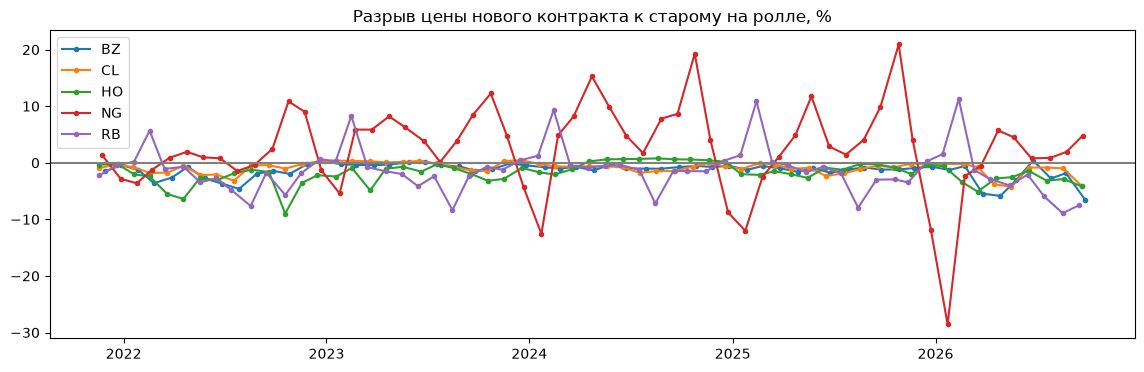

медиана |доходности| на барах ролла, склеенный ряд: 0.13
то же без склейки: 1.37
первый бар сессии без ролла: 0.12


In [15]:
prev_contract = fut.groupby("ticker")["contract"].shift()
prev_factor = fut.groupby("ticker")["factor"].shift()
rolls = fut[prev_contract.notna() & (fut["contract"] != prev_contract)].copy()
rolls["разрыв, %"] = (prev_factor[rolls.index] / rolls["factor"] - 1) * 100

display(rolls.groupby("ticker")["разрыв, %"].agg(["count", "median", "min", "max"]).round(2))

fig, ax = plt.subplots(figsize=(14, 4))
for ticker, g in rolls.groupby("ticker"):
    ax.plot(g["time"], g["разрыв, %"], marker=".", label=ticker)
ax.axhline(0, color="gray")
ax.set_title("Разрыв цены нового контракта к старому на ролле, %")
ax.legend()
plt.show()

raw_close = fut["close"] / fut["factor"]
raw_ret = np.log(raw_close / raw_close.groupby(fut["ticker"]).shift()) * 100
print("медиана |доходности| на барах ролла, склеенный ряд:", rolls["ret"].abs().median().round(2))
print("то же без склейки:", raw_ret[rolls.index].abs().median().round(2))
first_no_roll = fut[fut["first_bar"] & ~fut.index.isin(rolls.index)]
print("первый бар сессии без ролла:", first_no_roll["ret"].abs().median().round(2))

Ролл примерно раз в месяц, всего 59 за период. У нефти и нефтепродуктов следующий контракт
обычно немного дешевле текущего. У NG и RB разрыв меняется по сезонам и каждый год повторяется.
У NG в конце октября следующий контракт уже зимний и дороже (до +21%), а в декабре–январе
следующий ближе к весне и дешевле (до −29%). У RB в феврале следующий контракт уже на летний
бензин и дороже, а в августе — на зимний и дешевле.

Ролл всегда приходится на первый бар сессии. Без склейки там был бы скачок около 1,4%,
а в склеенном ряду почти как у первого бара без ролла (0,13% против 0,12%), значит склейка работает.

## 6. Стационарность и автокорреляция

Тесты делаю на дневных данных (последняя цена сессии). ADF: p < 0.05 значит ряд стационарен.
KPSS наоборот: p < 0.05 значит нестационарен. Беру оба, чтобы они проверяли друг друга.

In [16]:
warnings.filterwarnings("ignore", message=".*outside of the range of p-values.*")


def test_pvalues(series):
    s = series.dropna()
    return adfuller(s, result_object=True).pvalue, kpss(s, nlags="auto", result_object=True).pvalue


rows = []
for market, df in [("фьючерсы", fut), ("акции", stk_main)]:
    log_price = np.log(df.groupby(["ticker", "session_end_date"])["close"].last())
    for ticker, price in log_price.groupby(level="ticker"):
        adf_price, kpss_price = test_pvalues(price)
        adf_ret, kpss_ret = test_pvalues(price.diff())
        rows.append({"рынок": market, "ticker": ticker,
                     "ADF цена": adf_price, "KPSS цена": kpss_price,
                     "ADF доходность": adf_ret, "KPSS доходность": kpss_ret})

tests = pd.DataFrame(rows).round(3)
display(tests[tests["рынок"] == "фьючерсы"])

tests["цена нестационарна"] = (tests["ADF цена"] > 0.05) & (tests["KPSS цена"] < 0.05)
tests["доходность стационарна"] = (tests["ADF доходность"] < 0.05) & (tests["KPSS доходность"] > 0.05)
display(tests.groupby("рынок")[["цена нестационарна", "доходность стационарна"]].sum())
tests[~tests["цена нестационарна"] | ~tests["доходность стационарна"]]

,рынок,ticker,ADF цена,KPSS цена,ADF доходность,KPSS доходность
0,фьючерсы,BZ,0.598,0.01,0.0,0.1
1,фьючерсы,CL,0.262,0.01,0.0,0.1
2,фьючерсы,HO,0.785,0.01,0.0,0.1
3,фьючерсы,NG,0.654,0.01,0.0,0.1
4,фьючерсы,RB,0.862,0.01,0.0,0.1


,цена нестационарна,доходность стационарна
рынок,,
акции,29,30
фьючерсы,5,5


,рынок,ticker,ADF цена,KPSS цена,ADF доходность,KPSS доходность,цена нестационарна,доходность стационарна
28,акции,SBUX,0.025,0.01,0.0,0.1,False,True


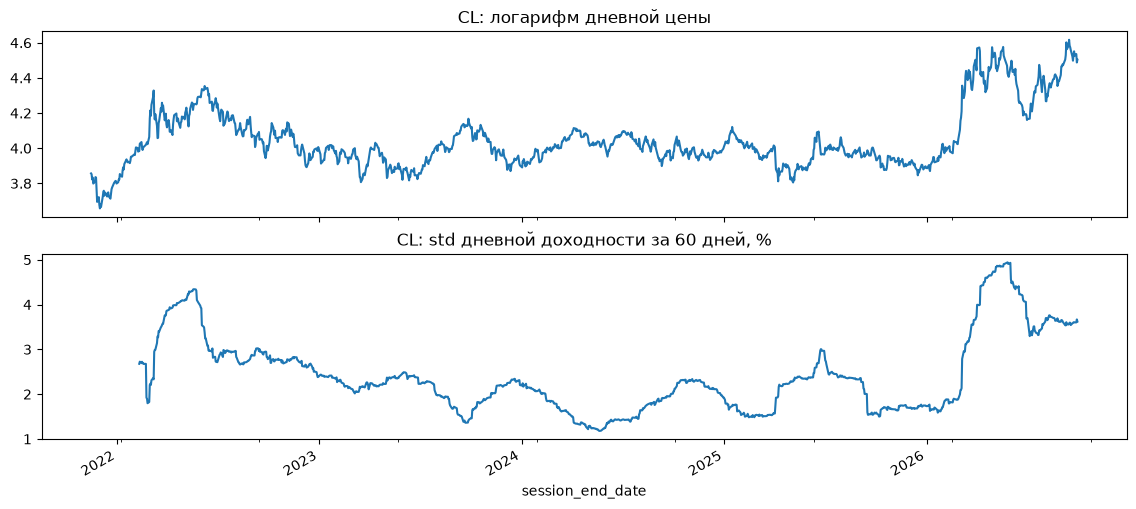

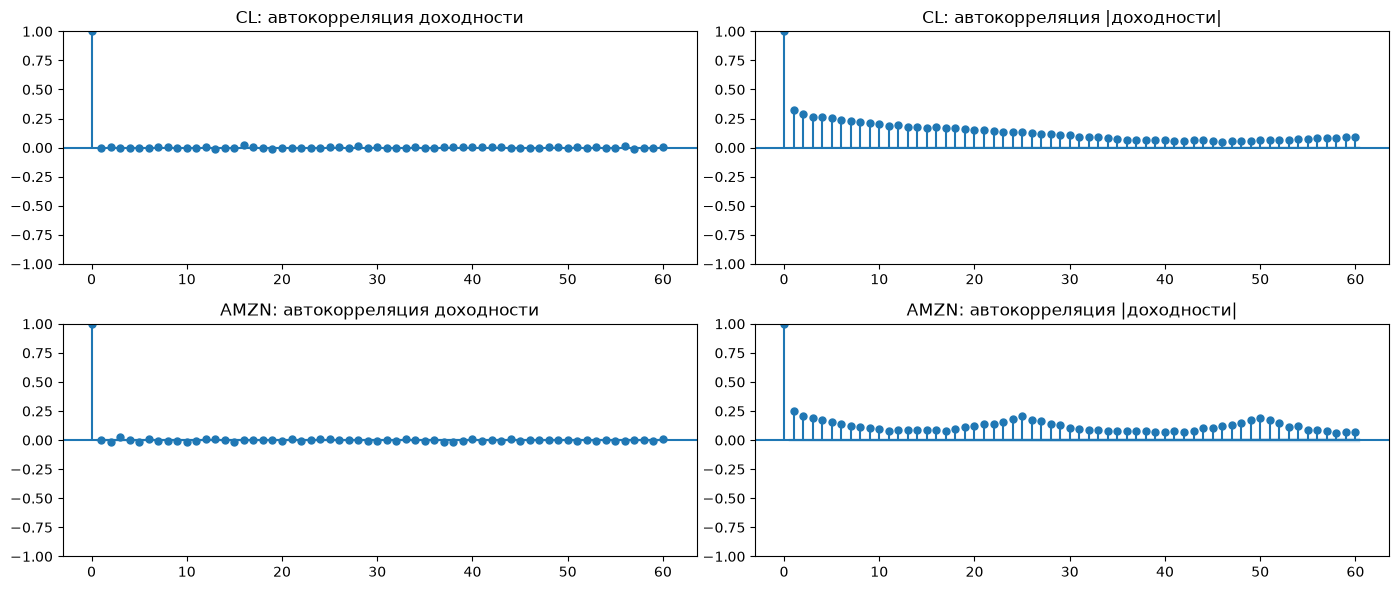

,доходность,|доходность|
min,-0.024,0.198
50%,-0.007,0.242
max,0.016,0.332


In [17]:
cl = np.log(fut[fut["ticker"] == "CL"].groupby("session_end_date")["close"].last())
cl.index = pd.to_datetime(cl.index)
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
cl.plot(ax=axes[0], title="CL: логарифм дневной цены")
(cl.diff().rolling(60).std() * 100).plot(ax=axes[1], title="CL: std дневной доходности за 60 дней, %")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 6))
for row, (name, data) in enumerate([("CL", fut_in[fut_in["ticker"] == "CL"]),
                                    ("AMZN", stk_in[stk_in["ticker"] == "AMZN"])]):
    r = data["ret"].dropna()
    plot_acf(r, lags=60, ax=axes[row, 0], title=f"{name}: автокорреляция доходности")
    plot_acf(r.abs(), lags=60, ax=axes[row, 1], title=f"{name}: автокорреляция |доходности|")
plt.tight_layout()
plt.show()

lag1 = []
for df in [fut_in, stk_in]:
    for ticker, g in df.groupby("ticker"):
        r = g["ret"].dropna()
        lag1.append({"ticker": ticker, "доходность": r.autocorr(1), "|доходность|": r.abs().autocorr(1)})
pd.DataFrame(lag1).set_index("ticker").describe().loc[["min", "50%", "max"]].round(3)

Цена нестационарна у всех фьючерсов и у 29 акций из 30, доходность стационарна у всех.
У SBUX тесты по цене расходятся (строка выше): за 5 лет она ходила в коридоре и вернулась примерно туда же.
Значит, дальше работать с доходностями, а не с ценами.

Цена гуляет без постоянного уровня, а волатильность то растёт, то падает (2022 и 2026 годы).
Доходность стационарна в среднем, но её разброс меняется со временем.

Сама доходность почти не связана со своим прошлым: на лаге 1 у всех 35 тикеров от −0,02 до 0,02,
то есть направление по прошлому не угадать. А модуль доходности связан заметно (0,2–0,33): после
сильного движения обычно снова сильное. Это кластеры волатильности. У AMZN горбы через каждые
25 баров — это один торговый день, повторяется дневной профиль. То есть размер движения
повторяется, а направление нет.

## 7. Корреляции

Беру дневные доходности: одна строка на торговый день.

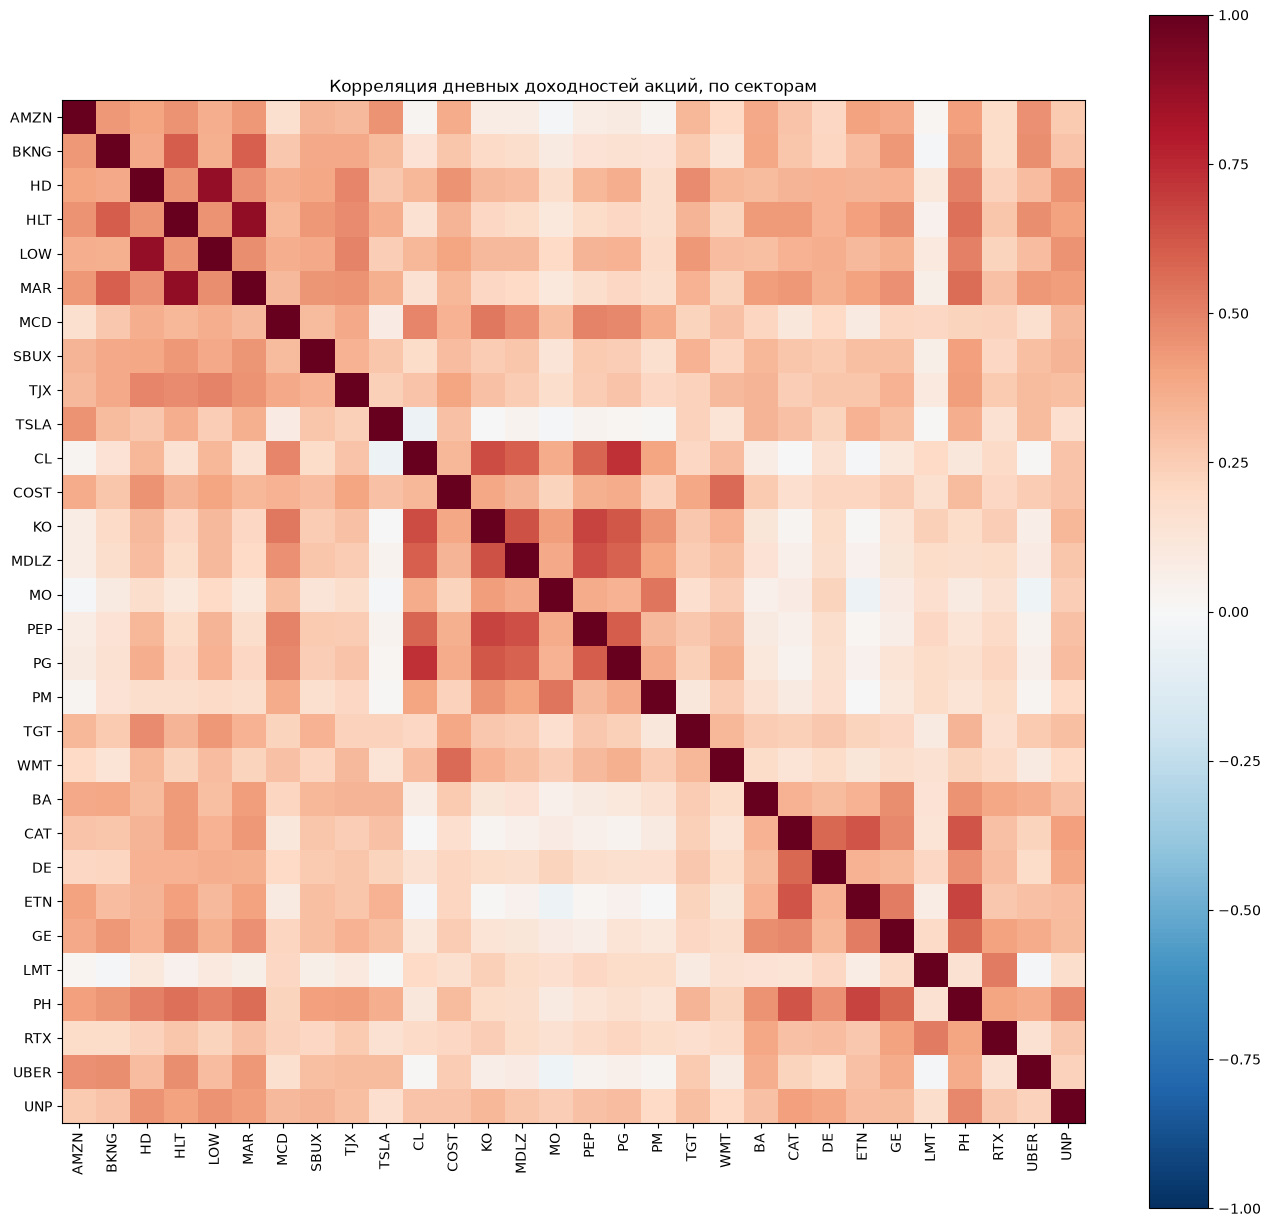

внутри сектора 0.38, между секторами 0.23
меньше всего связаны с остальными: {'LMT': 0.14, 'MO': 0.18, 'TSLA': 0.2, 'PM': 0.21}


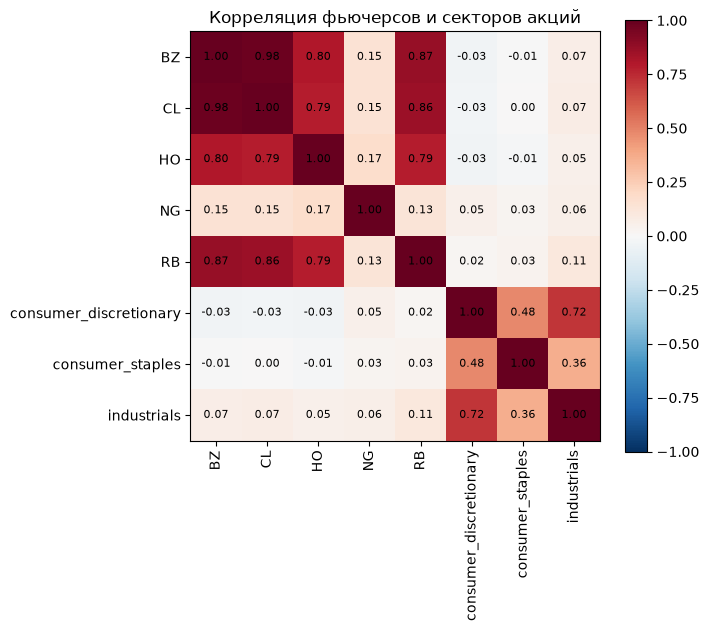

In [18]:
def daily_returns(df):
    close = df.groupby(["session_end_date", "ticker"])["close"].last().unstack()
    return np.log(close).diff()


def plot_corr(corr, title, numbers=False):
    fig, ax = plt.subplots(figsize=(len(corr) * 0.45 + 3, len(corr) * 0.45 + 2))
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)), corr.index)
    if numbers:
        for i in range(len(corr)):
            for j in range(len(corr)):
                ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=ax)
    ax.set_title(title)
    plt.show()


fut_daily = daily_returns(fut)
stk_daily = daily_returns(stk_main)

order = sorted(stocks, key=lambda t: (stocks[t], t))
stk_corr = stk_daily[order].corr()
plot_corr(stk_corr, "Корреляция дневных доходностей акций, по секторам")

same, other = [], []
for a in order:
    for b in order:
        if a < b:
            (same if stocks[a] == stocks[b] else other).append(stk_corr.loc[a, b])
print(f"внутри сектора {np.mean(same):.2f}, между секторами {np.mean(other):.2f}")

mean_corr = (stk_corr.sum() - 1) / (len(order) - 1)  # средняя корреляция с остальными, без себя
print("меньше всего связаны с остальными:", mean_corr.nsmallest(4).round(2).to_dict())

sector_daily = pd.DataFrame({
    sector: stk_daily[[t for t in stocks if stocks[t] == sector]].mean(axis=1)
    for sector in my_groups["stocks"]
})
both = pd.concat([fut_daily, sector_daily], axis=1).dropna()
plot_corr(both.corr(), "Корреляция фьючерсов и секторов акций", numbers=True)

На большой матрице видны блоки секторов: внутри сектора акции коррелируют в среднем на 0,38,
между секторами на 0,23. Сильнее всего связаны похожие компании: HD и LOW (строительные магазины),
HLT и MAR (отели), CL и PG (CL тут — акция Colgate-Palmolive, не нефть). Меньше всего связаны
с остальными LMT, MO, TSLA и PM.

Сектора тоже связаны между собой, сильнее всего Consumer Discretionary и Industrials (0,72).
Нефть, Brent, бензин и дизель двигаются почти одинаково (0,8–0,98), газ сам по себе (0,15).
С акциями наших секторов энергетика почти не связана.

Это связь в один и тот же день. Что одна бумага заранее подсказывает движение другой,
отсюда не следует.

## 8. Сделки (выборка)

Сторону сделки (покупка или продажа) определяю по котировкам: сделка по цене продавца — покупка,
по цене покупателя — продажа. Все сделки не гружу, беру один месяц в квартал (февраль, май,
август, ноябрь) и основной контракт, как в склеенном ряду. Сделки сразу свожу в 15-минутные бары.

In [19]:
TRADES_DIR = ROOT / "data/processed/futures_trades"
SAMPLE_MONTHS = [m for m in pd.period_range("2021-11", "2026-09", freq="M") if m.month in (2, 5, 8, 11)]


def load_trades(ticker, month):
    # основной контракт на каждый день берём из склеенного ряда
    days = fut[(fut["ticker"] == ticker) & fut["session_end_date"].str.startswith(str(month))]
    front = days.groupby("session_end_date")["contract"].first()
    parts = []
    for contract in front.unique():
        path = TRADES_DIR / ticker / contract / f"{month}.parquet"
        t = pd.read_parquet(path, columns=["timestamp", "size", "session_end_date", "est_side"])
        parts.append(t[t["session_end_date"].map(front) == contract])
    return pd.concat(parts)


bars, sizes = [], {}
for ticker in futures:
    sizes[ticker] = pd.Series(dtype=float)
    for month in SAMPLE_MONTHS:
        trades = load_trades(ticker, month)
        trades["time"] = pd.to_datetime(trades["timestamp"], utc=True).dt.floor("15min").dt.tz_convert("America/New_York")
        trades["signed"] = trades["size"] * trades["est_side"]
        b = trades.groupby("time").agg(trades=("size", "size"), volume=("size", "sum"),
                                       imbalance=("signed", "sum")).reset_index()
        b["ticker"] = ticker
        bars.append(b)
        sizes[ticker] = sizes[ticker].add(trades["size"].value_counts(), fill_value=0)

flow = pd.concat(bars, ignore_index=True)

объём сделок / объём баров: 1.0002


,"сделок, млн","по 1 контракту, %",99% сделок не больше,макс
ticker,,,,
CL,45.1,69,12,1158
NG,18.2,65,14,1000
BZ,4.4,79,6,250
RB,8.0,86,4,240
HO,7.7,86,4,243


,с доходностью этого бара,со следующим баром
ticker,,
BZ,0.158,-0.005
CL,0.378,-0.004
HO,0.133,-0.012
NG,0.325,-0.003
RB,0.125,-0.003


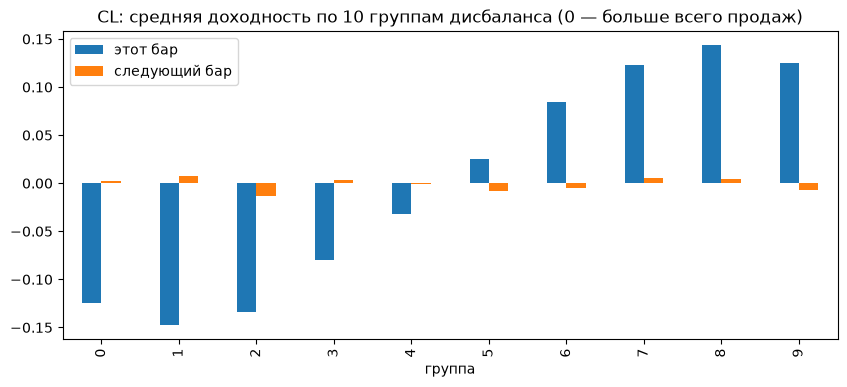

In [20]:
fut["ret_next"] = fut.groupby("ticker")["ret"].shift(-1)
flow = flow.merge(fut[["ticker", "time", "volume", "ret", "ret_next", "first_bar"]],
                  on=["ticker", "time"], suffixes=("", "_bar"))
print("объём сделок / объём баров:", round(flow["volume"].sum() / flow["volume_bar"].sum(), 4))

rows = []
for ticker, s in sizes.items():
    share = s.sort_index() / s.sum()
    rows.append({"ticker": ticker, "сделок, млн": round(s.sum() / 1e6, 1),
                 "по 1 контракту, %": round(share.loc[1] * 100),
                 "99% сделок не больше": share.cumsum()[share.cumsum() >= 0.99].index[0],
                 "макс": int(s.index.max())})
display(pd.DataFrame(rows).set_index("ticker"))

flow["imb"] = flow["imbalance"] / flow["volume"]
inside = flow[~flow["first_bar"]]

rows = []
for ticker, g in inside.groupby("ticker"):
    rows.append({"ticker": ticker,
                 "с доходностью этого бара": g["imb"].corr(g["ret"]),
                 "со следующим баром": g["imb"].corr(g["ret_next"])})
display(pd.DataFrame(rows).set_index("ticker").round(3))

cl_flow = inside[inside["ticker"] == "CL"].copy()
cl_flow["группа"] = pd.qcut(cl_flow["imb"], 10, labels=False)
means = cl_flow.groupby("группа")[["ret", "ret_next"]].mean()
means.columns = ["этот бар", "следующий бар"]
means.plot.bar(
    figsize=(10, 4), title="CL: средняя доходность по 10 группам дисбаланса (0 — больше всего продаж)")
plt.show()

Объём сделок совпадает с объёмом баров, значит сделки и бары согласованы.

В основном торгуют по 1 контракту (65–86% сделок), крупные сделки редкие.

Дисбаланс покупок и продаж хорошо связан с движением цены в том же баре: у CL 0,38, у NG 0,33.
Когда больше покупают, цена растёт (график). Но на следующий бар он почти не влияет (около 0).
У BZ, HO и RB связь слабее: скорее всего, там много сделок между разными контрактами (спредов),
и их сторону по котировкам определить сложнее.

## Рекомендации по данным

- у NG 20.02.2025 оставить больший кусок разрезанного бара, 4-часовые бары фьючерсов не использовать
  (там много таких разрезанных баров)
- пропуски не заполнять: у фьючерсов это в основном ночные 15 минут без сделок, у акций их почти нет,
  у BKNG это правило о полном лоте. Если нужен ровный ряд — заполнить прошлой ценой и нулевым объёмом
- выбросы не удалять, это настоящие движения (отчёты компаний, новости, конфликты)
- первый бар каждой сессии отметить: его доходность считается от закрытия прошлого дня, то есть
  за всю ночь или выходные, а не за 15 минут. Данные не удаляем, просто учитываем, что это
  другой промежуток времени
- брать доходности, а не цены: цены нестационарны
- у акций брать цены с поправкой на сплиты и дивиденды, у фьючерсов — склеенный ряд, склейка проверена
- время переводить в нью-йоркское, день недели и месяц у фьючерсов считать по торговой сессии